# NN_L12_rag_recall

**Recall@k of four retrievers (TF-IDF, BM25, dense bge-small embeddings, hybrid reciprocal rank fusion) that search 400 ECB speeches by their title.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_rag_recall/NN_L12_rag_recall.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

recall@1 tfidf (%) = 35.2   [rag.tfidf.r1]
mean reciprocal rank tfidf = 0.496   [rag.tfidf.mrr]
recall@1 bm25 (%) = 37.0   [rag.bm25.r1]
mean reciprocal rank bm25 = 0.515   [rag.bm25.mrr]
recall@1 dense (%) = 44.0   [rag.dense.r1]
mean reciprocal rank dense = 0.567   [rag.dense.mrr]
recall@1 hybrid (%) = 50.7   [rag.hybrid.r1]
mean reciprocal rank hybrid = 0.622   [rag.hybrid.mrr]


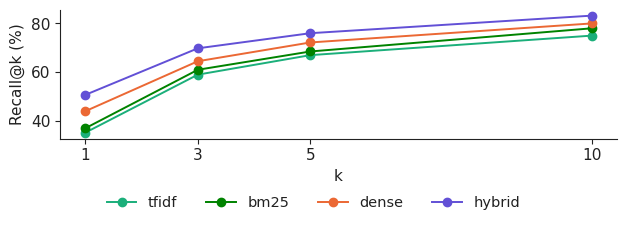

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
Rk = pd.read_csv(RES + 'rag_ranks.csv')
K = [1, 3, 5, 10]
fig, ax = plt.subplots(figsize=(6.4, 2.3))
for m, c in (('tfidf', PAL['benchmark']), ('bm25', SERIES[5]), ('dense', PAL['model']), ('hybrid', '#6250d6')):
    r = [round(100 * float((Rk[f'rank_{m}'] <= k).mean()), 1) for k in K]
    show(f'rag.{m}.r1', f'recall@1 {m} (%)', r[0])
    show(f'rag.{m}.mrr', f'mean reciprocal rank {m}', round(float((1 / Rk[f'rank_{m}']).mean()), 3))
    ax.plot(K, r, marker='o', color=c, label=m)
ax.set_xticks(K)
ax.set_xlabel('k')
ax.set_ylabel('Recall@k (%)')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('rag_recall.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()